In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from data.base import get_connection

YEAR = 2025
START = pd.Timestamp(YEAR, 1, 1)
END = pd.Timestamp(YEAR + 1, 1, 1)  # Excluded from the analysis.
OUTPUT = ROOT / "Fei" / "outputs" / f"time_comparison_{YEAR}"
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 130, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

In [3]:
con = get_connection()
TICKET_TABLES = [f"rlc_tickets_fy{year}" for year in range(2017, 2028)]
union_sql = " UNION ALL ".join(
    f"SELECT summons_number, issue_date, violation_code FROM {table}"
    for table in TICKET_TABLES
)
con.execute("CREATE OR REPLACE TEMP VIEW ticket_source AS " + union_sql)
con.execute("""
    CREATE OR REPLACE TEMP VIEW ticket_dates AS
    SELECT NULLIF(TRIM(summons_number), '') AS record_id,
           TRY_CAST(issue_date AS DATE) AS event_date,
           TRY_CAST(violation_code AS INTEGER) AS code
    FROM ticket_source
""")
con.execute("""
    CREATE OR REPLACE TEMP VIEW crash_dates AS
    SELECT NULLIF(TRIM(collision_id), '') AS record_id,
           TRY_CAST(crash_date AS DATE) AS event_date
    FROM crashes
""")
provenance = con.execute("SELECT * FROM _provenance").df()
provenance = provenance[provenance.table_name.isin(["crashes", *TICKET_TABLES])]
provenance.to_csv(OUTPUT / "source_provenance.csv", index=False)
print("Reading existing local caches; no download needed.")

Reading existing local caches; no download needed.


In [4]:
quality_rows = []
for name, table in [("Crashes", "crash_dates"), ("Red-light tickets", "ticket_dates")]:
    checks = con.execute(f"""
        SELECT COUNT(*) AS raw_rows,
               COUNT(DISTINCT record_id) AS unique_ids,
               COUNT(*) FILTER (WHERE record_id IS NULL) AS missing_ids,
               COUNT(*) FILTER (WHERE event_date IS NULL) AS invalid_dates,
               MIN(event_date) AS first_date, MAX(event_date) AS last_date
        FROM {table}
    """).df().iloc[0].to_dict()
    conflicts = con.execute(f"""
        SELECT COUNT(*) FROM (
            SELECT record_id FROM {table}
            GROUP BY record_id HAVING COUNT(DISTINCT event_date) > 1
        )
    """).fetchone()[0]
    checks.update(dataset=name, conflicting_date_ids=conflicts)
    checks["repeat_rows"] = checks["raw_rows"] - checks["unique_ids"]
    quality_rows.append(checks)

quality = pd.DataFrame(quality_rows).set_index("dataset")
display(quality)
quality.to_csv(OUTPUT / "data_quality.csv")
assert quality[["missing_ids", "invalid_dates", "conflicting_date_ids"]].eq(0).all().all(), "Review ID/date issues before counting."
assert con.execute("SELECT COUNT(*) FROM ticket_dates WHERE code IS NULL OR code <> 7").fetchone()[0] == 0
assert (pd.to_datetime(quality.first_date) <= START).all(), "The cache starts after the analysis period."
assert (pd.to_datetime(quality.last_date) >= END - pd.Timedelta(days=1)).all(), "The chosen year is not fully covered by these caches."

,raw_rows,unique_ids,missing_ids,invalid_dates,first_date,last_date,conflicting_date_ids,repeat_rows
dataset,,,,,,,,
Crashes,1311313,1311313,0,0,2017-01-01,2026-06-11,0,0
Red-light tickets,6334169,6136150,0,0,2016-05-21,2026-07-26,0,198019


## Count unique events per day

In [5]:
daily_tables = []
for table, column in [("crash_dates", "crashes"), ("ticket_dates", "red_light_tickets")]:
    daily = con.execute(f"""
        SELECT event_date, COUNT(*) AS {column}
        FROM (SELECT DISTINCT record_id, event_date FROM {table})
        WHERE event_date >= ? AND event_date < ?
        GROUP BY event_date ORDER BY event_date
    """, [START.date(), END.date()]).df()
    daily["event_date"] = pd.to_datetime(daily.event_date)
    daily_tables.append(daily.set_index("event_date"))

calendar = pd.date_range(START, END, freq="D", inclusive="left", name="date")
daily_counts = pd.concat(daily_tables, axis=1).reindex(calendar)
# An absent day needs investigation; do not silently turn missing data into zero.
assert not daily_counts.isna().any().any(), "Some days have no records. Investigate coverage before plotting."
daily_counts = daily_counts.astype("int64")
con.close()
print(f"Both datasets contain records on all {len(daily_counts)} calendar days.")
display(daily_counts.head())

Both datasets contain records on all 365 calendar days.


,crashes,red_light_tickets
date,,
2025-01-01,188,1343
2025-01-02,201,1202
2025-01-03,212,1634
2025-01-04,176,1539
2025-01-05,174,1424


## Summarize by month

In [6]:
monthly = daily_counts.resample("MS").sum()
monthly.index.name = "month"
monthly["days_in_month"] = monthly.index.days_in_month
monthly["crashes_per_day"] = monthly.crashes / monthly.days_in_month
monthly["red_light_tickets_per_day"] = monthly.red_light_tickets / monthly.days_in_month
assert len(monthly) == 12
assert monthly[["crashes", "red_light_tickets"]].sum().equals(daily_counts.sum())
daily_counts.to_csv(OUTPUT / "daily_counts.csv")
monthly.to_csv(OUTPUT / "monthly_comparison.csv")
display(monthly.round(2))

,crashes,red_light_tickets,days_in_month,crashes_per_day,red_light_tickets_per_day
month,,,,,
2025-01-01,6482,43972,31,209.10,1418.45
2025-02-01,5988,40343,28,213.86,1440.82
2025-03-01,7035,52578,31,226.94,1696.06
2025-04-01,6924,50418,30,230.80,1680.60
2025-05-01,7636,57003,31,246.32,1838.81
2025-06-01,7483,56894,30,249.43,1896.47
2025-07-01,7410,59377,31,239.03,1915.39
2025-08-01,6989,61858,31,225.45,1995.42
2025-09-01,7537,63396,30,251.23,2113.20


## Compare monthly totals

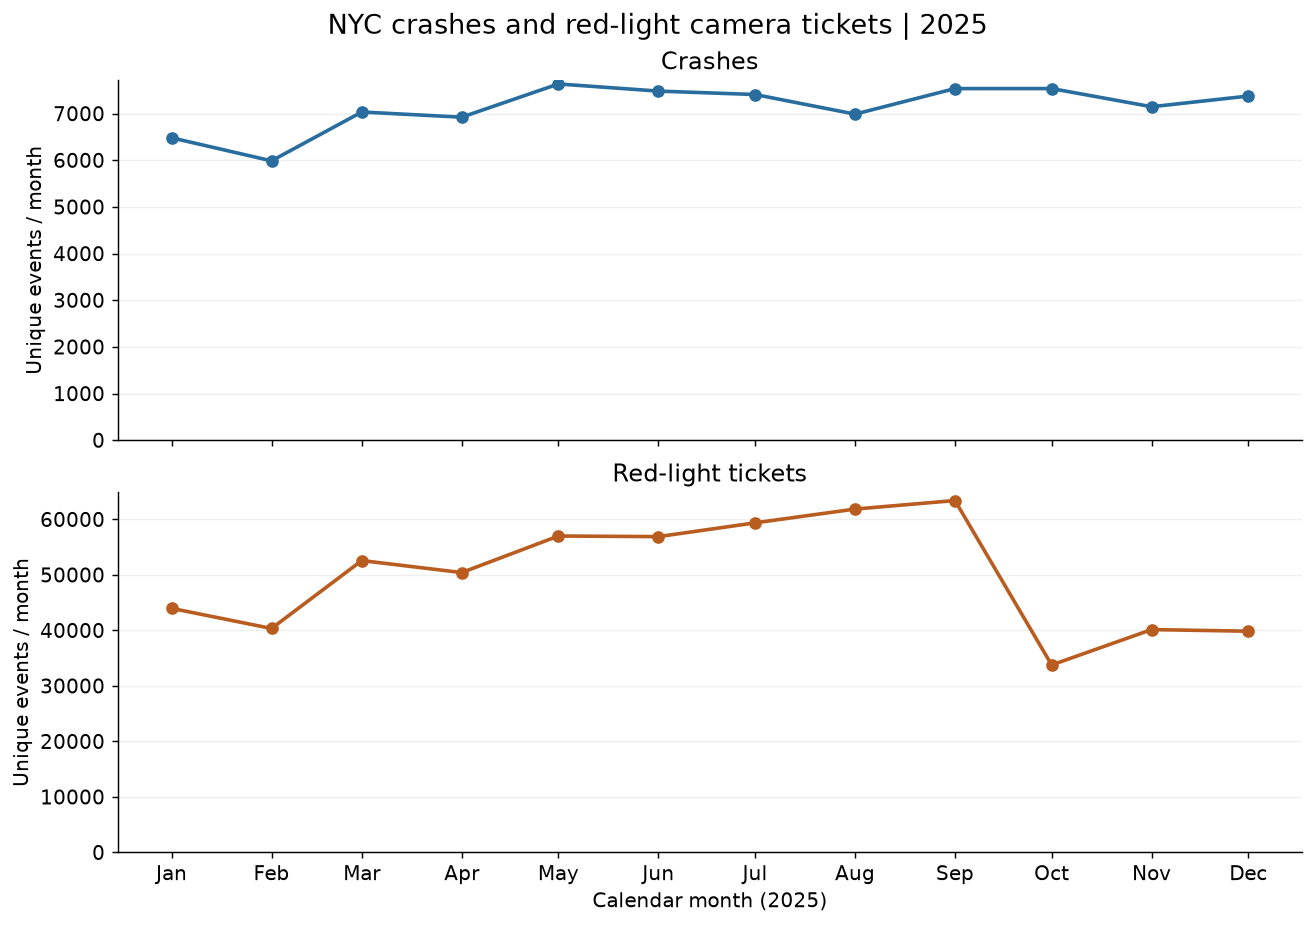

In [7]:
colors = ["#286D9E", "#B85C20"]
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, layout="constrained")
for ax, column, label, color in zip(axes, ["crashes", "red_light_tickets"],
                                  ["Crashes", "Red-light tickets"], colors):
    ax.plot(monthly.index, monthly[column], marker="o", color=color, linewidth=2)
    ax.set(title=label, ylabel="Unique events / month", ylim=(0, None))
    ax.grid(axis="y", alpha=0.2)
axes[-1].set_xticks(monthly.index, monthly.index.strftime("%b"))
axes[-1].set_xlabel(f"Calendar month ({YEAR})")
fig.suptitle(f"NYC crashes and red-light camera tickets | {YEAR}", fontsize=15)
fig.savefig(OUTPUT / "monthly_totals.png", dpi=180)
plt.show()

##  Compare daily averages within each month


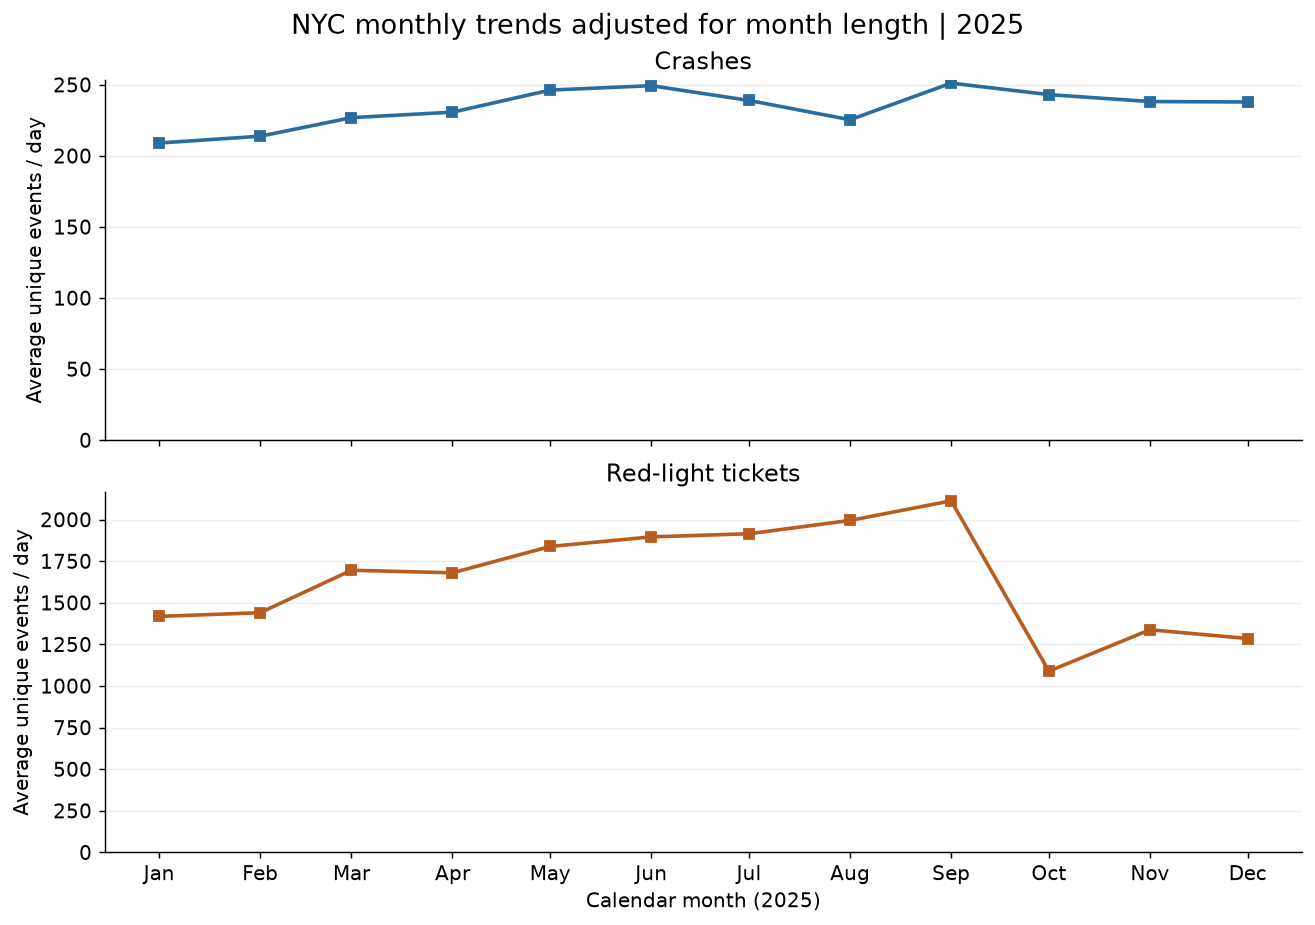

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, layout="constrained")
for ax, column, label, color in zip(axes, ["crashes_per_day", "red_light_tickets_per_day"],
                                  ["Crashes", "Red-light tickets"], colors):
    ax.plot(monthly.index, monthly[column], marker="s", color=color, linewidth=2)
    ax.set(title=label, ylabel="Average unique events / day", ylim=(0, None))
    ax.grid(axis="y", alpha=0.2)
axes[-1].set_xticks(monthly.index, monthly.index.strftime("%b"))
axes[-1].set_xlabel(f"Calendar month ({YEAR})")
fig.suptitle(f"NYC monthly trends adjusted for month length | {YEAR}", fontsize=15)
fig.savefig(OUTPUT / "daily_averages.png", dpi=180)
plt.show()

## Read the results

In [9]:
for column, label in [("crashes", "Crashes"), ("red_light_tickets", "Red-light tickets")]:
    peak = monthly[column].idxmax()
    daily_peak = monthly[f"{column}_per_day"].idxmax()
    print(f"{label}: {monthly[column].sum():,} unique events in {YEAR}.")
    print(f"  Highest monthly total: {peak:%B} ({monthly.loc[peak, column]:,}).")
    print(f"  Highest daily average: {daily_peak:%B} ({monthly.loc[daily_peak, column + '_per_day']:,.1f}/day).")
print("Saved tables, source provenance, and figures to:", OUTPUT.relative_to(ROOT))

Crashes: 85,546 unique events in 2025.
  Highest monthly total: May (7,636).
  Highest daily average: September (251.2/day).
Red-light tickets: 599,611 unique events in 2025.
  Highest monthly total: September (63,396).
  Highest daily average: September (2,113.2/day).
Saved tables, source provenance, and figures to: Fei/outputs/time_comparison_2025
